# Customer Churn Prediction


## 1. Import Required Libraries



In [483]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 2. Load Dataset


In [484]:
df = pd.read_csv(r"C:\Users\humai\Intern\Telco\Data\WA_Fn-UseC_-Telco-Customer-Churn.csv")

## 3. Preview Dataset

In [485]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Understand Dataset Structure


In [486]:
# Data Shape
df.shape

(7043, 21)

In [487]:
# Data Columns
df.columns


Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## 5. Check Data Types

In [488]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

## 6. Check Missing Values

In [489]:
# Missing Values in the dataset
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [490]:
# Checking for empty strings in the dataset
(df == " ").sum()


customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [491]:
# Checking for empty strings in the "TotalCharges" column
df[df["TotalCharges"] == " "]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


## 7. Clean Data

In [492]:
# Converting the "TotalCharges" column to numeric type, coercing errors to NaN
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [493]:
# Data Type of "TotalCharges" column
df["TotalCharges"].dtype

dtype('float64')

In [494]:
# Dataset Information after converting "TotalCharges" to numeric type
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [495]:
# Checking for empty strings in the "TotalCharges" column
df[df["TotalCharges"] == " "]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn


In [496]:
# Dropping rows with missing values due to less than 1% of the dataset being affected
df = df.dropna()

In [497]:
# Data Shape after dropping rows with missing values
df.shape

(7032, 21)

In [498]:
# Count of null values in each column
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## 8. Exploratory Data Analysis (EDA)

In [499]:
# Count of Churn Values
df["Churn"].value_counts()

Churn
No     5163
Yes    1869
Name: count, dtype: int64

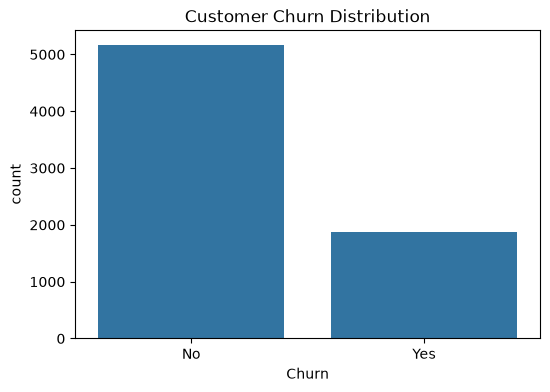

In [500]:
# Visualizing the distribution of the "Churn" column
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.savefig("../Images/exploratory_data_analysis/churn_distribution.png")
plt.show()

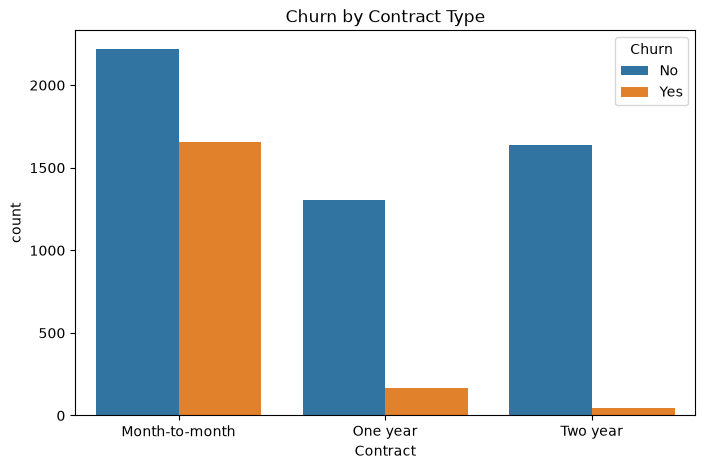

In [501]:
# Visualizing the distribution of the "Contract" column
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Churn by Contract Type")
plt.savefig("../Images/exploratory_data_analysis/churn_by_contract.png")
plt.show()

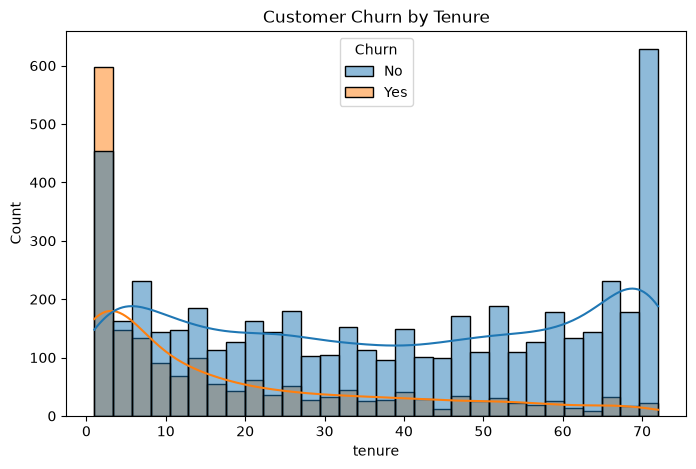

In [502]:
# Visualizing the distribution of the "tenure" column
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="tenure", hue="Churn", bins=30, kde=True)
plt.title("Customer Churn by Tenure")
plt.savefig("../Images/exploratory_data_analysis/churn_by_tenure.png")
plt.show()

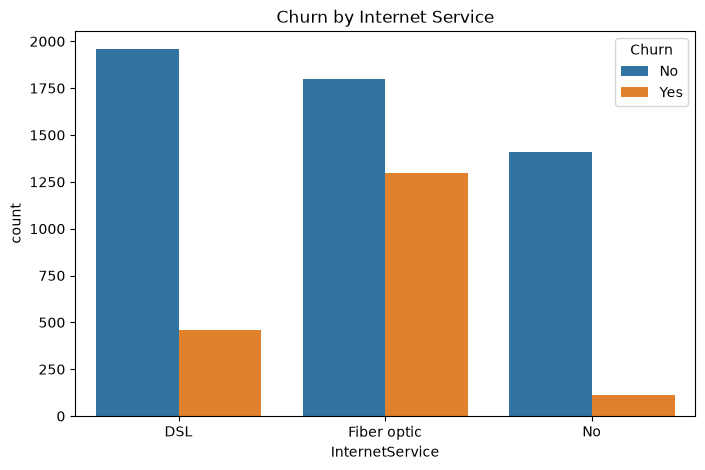

In [503]:
# Visualizing the distribution of the "InternetService" column
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="InternetService", hue="Churn")
plt.title("Churn by Internet Service")
plt.savefig("../Images/exploratory_data_analysis/churn_by_internet_service.png")
plt.show()

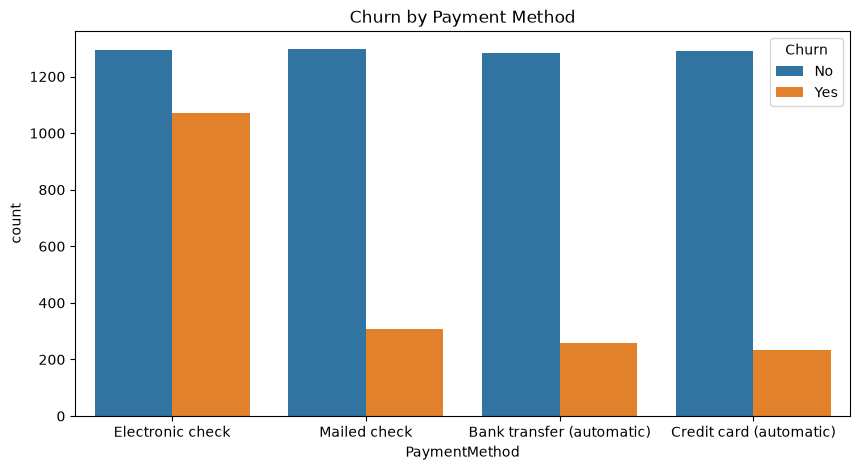

In [504]:
# Visualizing the distribution of the "PaymentMethod" column
plt.figure(figsize=(10,5))
sns.countplot(data=df, x="PaymentMethod", hue="Churn")
plt.title("Churn by Payment Method")
plt.savefig("../Images/exploratory_data_analysis/churn_by_payment_method.png")
plt.show()

### 1. Churn Distribution

**Observation:**

* Most customers stay with the company, while a smaller number choose to leave.
* Although the majority of customers do not churn, the number of customers who leave is still significant enough to make churn prediction an important business problem.

---

### 2. Churn by Contract Type

**Observation:**

* Customers with **month-to-month contracts** are much more likely to churn than customers with longer contracts.
* Customers on **one-year** and **two-year contracts** are more likely to stay with the company, with two-year contract customers showing the lowest churn.
* This suggests that longer contract commitments are linked to better customer retention.

---

### 3. Churn by Tenure

**Observation:**

* Customers who have recently joined the company are more likely to churn.
* As customers stay with the company for a longer period, the chances of them leaving decrease.
* This indicates that long-term customers tend to be more loyal.

---

### 4. Churn by Internet Service

**Observation:**

* Customers using **Fiber optic** internet service have a higher churn rate than those using **DSL** or **No internet service**.
* This could indicate that customers using fiber optic service may have different expectations or experiences that influence their decision to leave.
* Further investigation is needed to understand the exact reason behind this pattern.

---

### 5. Churn by Payment Method

**Observation:**

* Customers who pay using **Electronic check** have the highest churn rate.
* Customers using **automatic payment methods**, such as bank transfer or credit card, are less likely to churn.
* This suggests that customers enrolled in automatic payments may be more likely to remain with the company.

---

## Overall EDA Summary

**Key Findings:**

* Most customers remain with the company, but a considerable number still churn.
* Customers with month-to-month contracts are more likely to leave than those with long-term contracts.
* New customers are at a higher risk of churning, while long-term customers are generally more loyal.
* Fiber optic customers show higher churn compared to other internet service users.
* Customers paying through electronic checks tend to churn more than those using automatic payment methods.




## 9. Feature Engineering

In [505]:
# Examine the numerical columns in the dataset
df.select_dtypes(include="number").columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

### Feature Engineering

After reviewing the available features, no additional features were created at this stage. The existing variables already capture useful customer information, and creating derived variables such as **TotalCharges / tenure** would largely duplicate the information already represented by **MonthlyCharges**.

Therefore, the existing features will be used for the next preprocessing stage.



## 10. Data Preprocessing

In [506]:
# Identify the numerical columns in the dataset
df.select_dtypes(include="number").columns

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='str')

In [507]:
# Identify the categorical columns in the dataset
df.select_dtypes(include="object").columns

Index(['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService',
       'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
       'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies',
       'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [508]:
# Dropping the "customerID" column as it is not useful for analysis
df.drop("customerID", axis=1, inplace=True)

In [509]:
# Viewing the columns of the dataset after dropping "customerID"
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [510]:
# Identify the categorical columns in the dataset after dropping "customerID"
df.select_dtypes(include="object").columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'Churn'],
      dtype='str')

In [511]:
# Splitting the dataset into features (X) and target variable (y)
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [512]:
# Viewing the shape of the feature matrix
X.shape


(7032, 19)

In [513]:
# Viewing the shape of the target variable
y.shape

(7032,)

In [514]:
# Libraries for splitting the dataset into training and testing sets
from sklearn.model_selection import train_test_split

In [515]:
# Splitting the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [516]:
# Checking the shapes of the training and testing sets
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5625, 19), (1407, 19), (5625,), (1407,))

In [517]:
# Check the class distribution in the training and testing sets
y_train.value_counts(normalize=True), y_test.value_counts(normalize=True)

(Churn
 No     0.734222
 Yes    0.265778
 Name: proportion, dtype: float64,
 Churn
 No     0.734186
 Yes    0.265814
 Name: proportion, dtype: float64)

In [518]:
# Libraries for preprocessing the data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [519]:
# Identify numeric and categorical features
numeric_features = X_train.select_dtypes(include="number").columns.tolist()

categorical_features = X_train.select_dtypes(include="object").columns.tolist()

In [520]:
numeric_features

['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

In [521]:
categorical_features

['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [522]:
# Import library for scaling the numeric features
from sklearn.preprocessing import StandardScaler

In [523]:
# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features)
    ]
)

In [524]:
# Transform the training data
X_train_processed = preprocessor.fit_transform(X_train)

In [525]:
# Check the shape of the processed training data
X_train_processed.shape

(5625, 30)

In [526]:
# Transform the testing data
X_test_processed = preprocessor.transform(X_test)

In [527]:
X_test_processed.shape

(1407, 30)

## 11. Train-Test Split

In [528]:
# Check the shapes of the processed training and testing data
X_train_processed.shape, X_test_processed.shape

((5625, 30), (1407, 30))

## 12. Model Training

### 12.1 Logistic Regression

In [529]:
# Importing the Logistic Regression model from scikit-learn
from sklearn.linear_model import LogisticRegression

In [530]:
# Initialize the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000)

In [531]:
# View the initialized Logistic Regression model
logistic_model

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [532]:
# Train the Logistic Regression model on the processed training data
logistic_model.fit(X_train_processed, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

### 12.2 Decision Tree

In [533]:
# Importing the Decision Tree Classifier model from scikit-learn
from sklearn.tree import DecisionTreeClassifier

In [534]:
# Initialize the Decision Tree Classifier model
decision_tree_model = DecisionTreeClassifier(max_depth=5, random_state=42)

In [535]:
# View the parameters of the Decision Tree model
decision_tree_model

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

In [536]:
# Train the Decision Tree
decision_tree_model.fit(X_train_processed, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at 

### 12.3 Random Forest

In [537]:
# Importing the Random Forest Classifier model from scikit-learn
from sklearn.ensemble import RandomForestClassifier

In [538]:
# Initialize the Random Forest Classifier model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [539]:
# View the parameters of the Random Forest Classifier model
random_forest_model

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [540]:
# Train the Random Forest
random_forest_model.fit(X_train_processed, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

## 13. Model Evaluation

### 13.1 Predictions 

In [541]:
# Make Logistic Regression predictions on the test set
y_pred_logistic = logistic_model.predict(X_test_processed)

In [542]:
# View the first 10 predictions made by the Logistic Regression model
y_pred_logistic[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [543]:
# Make Decision Tree predictions on the test set
y_pred_tree = decision_tree_model.predict(X_test_processed)

In [544]:
# View the first 10 predictions made by the Decision Tree model
y_pred_tree[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

In [545]:
# Make Random Forest predictions on the test set
y_pred_rf = random_forest_model.predict(X_test_processed)

In [546]:
# View the first 10 predictions made by the Random Forest model
y_pred_rf[:10]

array(['No', 'Yes', 'No', 'No', 'No', 'No', 'No', 'No', 'Yes', 'No'],
      dtype=object)

### 13.2 Accuracy


In [547]:
# Importing the accuracy_score function from scikit-learn to evaluate model performance
from sklearn.metrics import accuracy_score

In [548]:
# Calculate Logistic Regression Accuracy
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_accuracy

0.8052594171997157

In [549]:
# Calculate Decision Tree Accuracy
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_accuracy

0.7782515991471215

In [550]:
# Calculate Random Forest Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_accuracy

0.7882018479033405

### 13.3 Precision


In [551]:
# Importing the precision_score function from scikit-learn to evaluate model performance
from sklearn.metrics import precision_score

In [552]:
# Calculate Logistic Regression Precision
logistic_precision = precision_score(y_test, y_pred_logistic, pos_label="Yes")
logistic_precision

0.6515151515151515

In [553]:
# Calculate Decision Tree Precision
tree_precision = precision_score(y_test, y_pred_tree, pos_label="Yes")
tree_precision

0.5807291666666666

In [554]:
# Calculate Random Forest Precision
rf_precision = precision_score(y_test, y_pred_rf, pos_label="Yes")
rf_precision

0.6233766233766234

### 13.4 Recall

In [555]:
# Importing the recall_score function from scikit-learn to evaluate model performance
from sklearn.metrics import recall_score

In [556]:
# Calculate Logistic Regression Recall
logistic_recall = recall_score(y_test, y_pred_logistic, pos_label="Yes")
logistic_recall

0.5748663101604278

In [557]:
# Calculate Decision Tree Recall
tree_recall = recall_score(y_test, y_pred_tree, pos_label="Yes")
tree_recall

0.5962566844919787

In [558]:
# Calculate Random Forest Recall
rf_recall = recall_score(y_test, y_pred_rf, pos_label="Yes")
rf_recall

0.5133689839572193

### 13.5 F1-Score


In [559]:
# Importing the f1_score function from scikit-learn to evaluate model performance
from sklearn.metrics import f1_score

In [560]:
# Calculate Logistic Regression f1 Score
logistic_f1 = f1_score(y_test, y_pred_logistic, pos_label="Yes")
logistic_f1

0.6107954545454546

In [561]:
# Calculate Decision Tree f1 Score
tree_f1 = f1_score(y_test, y_pred_tree, pos_label="Yes")
tree_f1

0.5883905013192612

In [562]:
# Calculate Random Forest f1 Score
rf_f1 = f1_score(y_test, y_pred_rf, pos_label="Yes")
rf_f1

0.5630498533724341

### 13.6 Compare Model Performance

In [563]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [logistic_accuracy, tree_accuracy, rf_accuracy],
    "Precision": [logistic_precision, tree_precision, rf_precision],
    "Recall": [logistic_recall, tree_recall, rf_recall],
    "F1-Score": [logistic_f1, tree_f1, rf_f1]
})
model_comparison.to_csv("../Outputs/model_comparison.csv", index=False)
model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.805259,0.651515,0.574866,0.610795
1,Decision Tree,0.778252,0.580729,0.596257,0.588391
2,Random Forest,0.788202,0.623377,0.513369,0.563050


### Observation:
Logistic Regression achieved the highest accuracy (80.53%), precision (65.15%), and F1-score (61.08%) among the three models. The Decision Tree achieved the highest recall (59.63%), meaning it identified a slightly larger proportion of actual churners. Random Forest performed below Logistic Regression on all four metrics in this experiment. Overall, Logistic Regression provides the best balance of performance, while the Decision Tree offers slightly better churn detection.

### 13.7 Confusion Matrix 

In [564]:
# Importing the confusion_matrix function from scikit-learn to evaluate model performance
from sklearn.metrics import confusion_matrix

#### Logistic Regression

In [565]:
# Calculate Logistic Regression Confusion Matrix
logistic_cm = confusion_matrix(y_test, y_pred_logistic, labels=["No", "Yes"])
logistic_cm

array([[918, 115],
       [159, 215]])

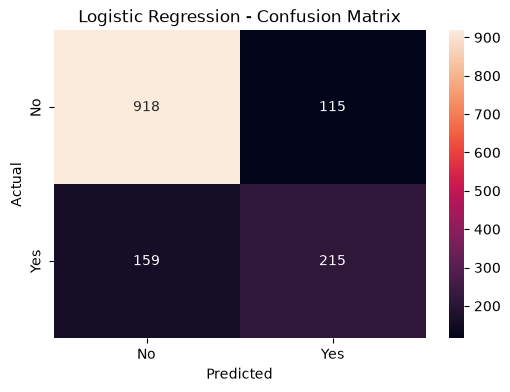

In [566]:
# Plot the confusion matrix 
plt.figure(figsize=(6, 4))

sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.savefig("../Images/confusion_matrix/logistic_regression_confusion_matrix.png")
plt.show()

#### Decision Tree

In [567]:
# Calculate Decision Tree Confusion Matrix
tree_cm = confusion_matrix(y_test, y_pred_tree, labels=["No", "Yes"])
tree_cm

array([[872, 161],
       [151, 223]])

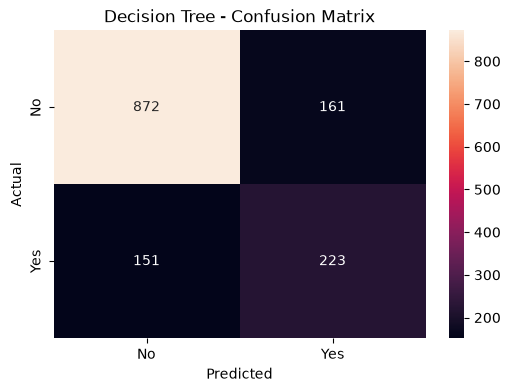

In [568]:
# Plot the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    tree_cm,
    annot=True,
    fmt="d",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")
plt.savefig("../Images/confusion_matrix/decision_tree_confusion_matrix.png")
plt.show()

#### Random Forest

In [569]:
# Calculate Random Forest Confusion Matrix
rf_cm = confusion_matrix(y_test, y_pred_rf, labels=["No", "Yes"])
rf_cm

array([[917, 116],
       [182, 192]])

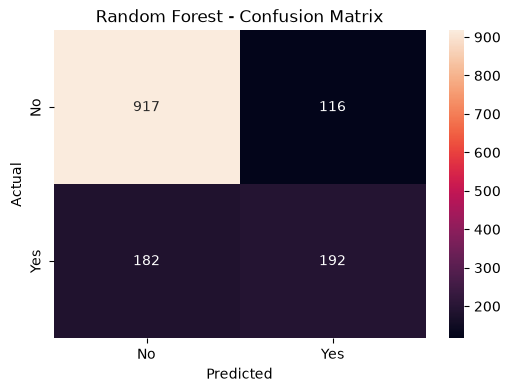

In [570]:
# Plot the confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.savefig("../Images/confusion_matrix/random_forest_confusion_matrix.png")
plt.show()

## 14. Feature Importance

### 14.1 Extract Decision Tree Feature Importance

In [571]:
tree_importance = decision_tree_model.feature_importances_
tree_importance

array([0.00930987, 0.4412833 , 0.02519761, 0.03388634, 0.        ,
       0.        , 0.        , 0.00758628, 0.        , 0.01013401,
       0.33882621, 0.        , 0.02677808, 0.0151383 , 0.        ,
       0.00906725, 0.        , 0.        , 0.        , 0.01215941,
       0.        , 0.        , 0.0154017 , 0.        , 0.00911129,
       0.01931153, 0.        , 0.        , 0.02680882, 0.        ])

In [572]:
# Mapping feature importance to feature names for Decision Tree
feature_names = preprocessor.get_feature_names_out()
feature_names

array(['num__SeniorCitizen', 'num__tenure', 'num__MonthlyCharges',
       'num__TotalCharges', 'cat__gender_Male', 'cat__Partner_Yes',
       'cat__Dependents_Yes', 'cat__PhoneService_Yes',
       'cat__MultipleLines_No phone service', 'cat__MultipleLines_Yes',
       'cat__InternetService_Fiber optic', 'cat__InternetService_No',
       'cat__OnlineSecurity_No internet service',
       'cat__OnlineSecurity_Yes', 'cat__OnlineBackup_No internet service',
       'cat__OnlineBackup_Yes',
       'cat__DeviceProtection_No internet service',
       'cat__DeviceProtection_Yes',
       'cat__TechSupport_No internet service', 'cat__TechSupport_Yes',
       'cat__StreamingTV_No internet service', 'cat__StreamingTV_Yes',
       'cat__StreamingMovies_No internet service',
       'cat__StreamingMovies_Yes', 'cat__Contract_One year',
       'cat__Contract_Two year', 'cat__PaperlessBilling_Yes',
       'cat__PaymentMethod_Credit card (automatic)',
       'cat__PaymentMethod_Electronic check',
       '

In [573]:
# Create the Feature Importance Table
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_importance
})

feature_importance_df

,Feature,Importance
0,num__SeniorCitizen,0.009310
1,num__tenure,0.441283
2,num__MonthlyCharges,0.025198
3,num__TotalCharges,0.033886
4,cat__gender_Male,0.000000
5,cat__Partner_Yes,0.000000
6,cat__Dependents_Yes,0.000000
7,cat__PhoneService_Yes,0.007586
8,cat__MultipleLines_No phone service,0.000000
9,cat__MultipleLines_Yes,0.010134


In [574]:
# Sort the feature importance table in descending order of importance
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df

,Feature,Importance
1,num__tenure,0.441283
10,cat__InternetService_Fiber optic,0.338826
3,num__TotalCharges,0.033886
28,cat__PaymentMethod_Electronic check,0.026809
12,cat__OnlineSecurity_No internet service,0.026778
2,num__MonthlyCharges,0.025198
25,cat__Contract_Two year,0.019312
22,cat__StreamingMovies_No internet service,0.015402
13,cat__OnlineSecurity_Yes,0.015138
19,cat__TechSupport_Yes,0.012159


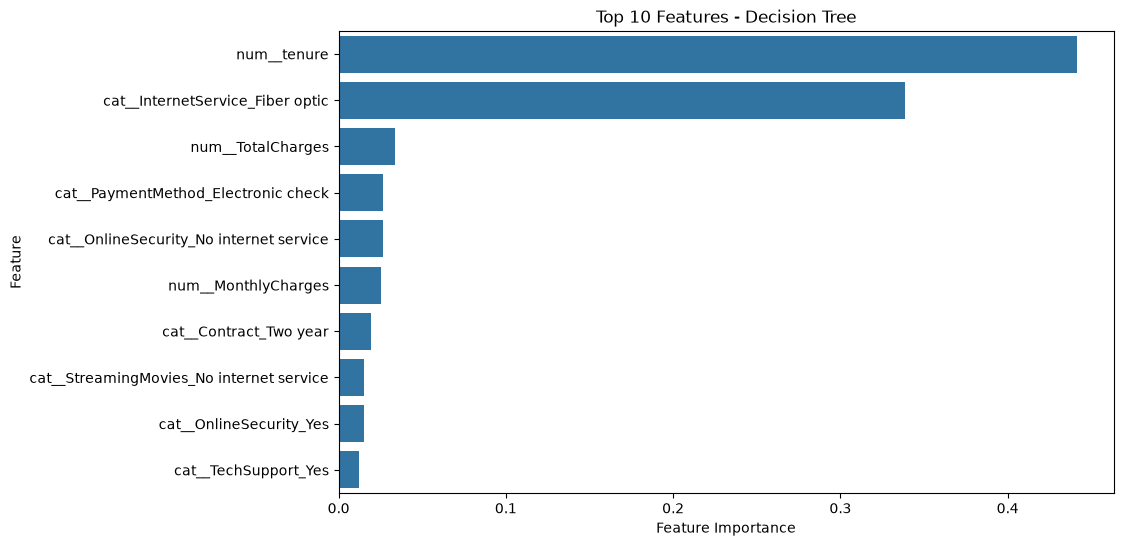

In [575]:
# Visualize the Top 10 Important Features
top_10_features = feature_importance_df.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_features,
    x="Importance",
    y="Feature"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features - Decision Tree")
plt.savefig("../Images/feature_importance/decision_tree_feature_importance.png")
plt.show()

### Observation: 
The Decision Tree identified tenure as the most influential feature in predicting customer churn, followed by fiber optic internet service. Total charges, payment method, online security, monthly charges, and contract type also contributed to the model's predictions, but with substantially lower importance. These results indicate that customer relationship duration and service characteristics are important predictive factors for churn. However, feature importance reflects predictive relationships and should not be interpreted as evidence of causation.

### 14.2 Extract Random Forest Feature Importance

In [576]:
rf_importance = random_forest_model.feature_importances_
rf_importance

array([0.02103481, 0.17102034, 0.16840004, 0.19143549, 0.02933205,
       0.0236819 , 0.01984634, 0.00435683, 0.00387208, 0.01958831,
       0.03948096, 0.00393622, 0.00700693, 0.02815702, 0.005896  ,
       0.02293206, 0.00908931, 0.01872788, 0.00445986, 0.02411376,
       0.00540368, 0.01652261, 0.00238027, 0.01770676, 0.02283552,
       0.03052915, 0.02553566, 0.01352819, 0.03741613, 0.01177385])

In [577]:
# Create the Feature Importance Table for Random Forest
rf_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

rf_importance_df

,Feature,Importance
0,num__SeniorCitizen,0.021035
1,num__tenure,0.171020
2,num__MonthlyCharges,0.168400
3,num__TotalCharges,0.191435
4,cat__gender_Male,0.029332
5,cat__Partner_Yes,0.023682
6,cat__Dependents_Yes,0.019846
7,cat__PhoneService_Yes,0.004357
8,cat__MultipleLines_No phone service,0.003872
9,cat__MultipleLines_Yes,0.019588


In [578]:
# Sort the feature importance table in descending order of importance
rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

rf_importance_df

,Feature,Importance
3,num__TotalCharges,0.191435
1,num__tenure,0.171020
2,num__MonthlyCharges,0.168400
10,cat__InternetService_Fiber optic,0.039481
28,cat__PaymentMethod_Electronic check,0.037416
25,cat__Contract_Two year,0.030529
4,cat__gender_Male,0.029332
13,cat__OnlineSecurity_Yes,0.028157
26,cat__PaperlessBilling_Yes,0.025536
19,cat__TechSupport_Yes,0.024114


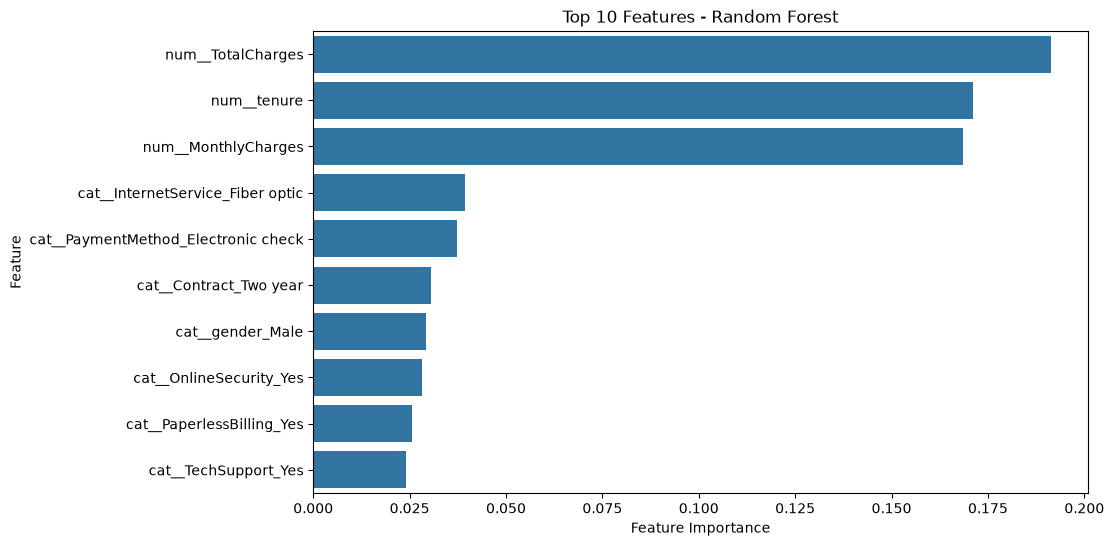

In [579]:
# Visualize the Top 10 Important Features for Random Forest
top_10_rf = rf_importance_df.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_rf,
    x="Importance",
    y="Feature"
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features - Random Forest")
plt.savefig("../Images/feature_importance/random_forest_feature_importance.png")
plt.show()

### **Observation:**
The Random Forest identified Total Charges, Tenure, and Monthly Charges as the most influential features, followed by Fiber optic internet service, electronic check payment method, and contract type. Several of these features were also highly important in the Decision Tree, particularly tenure, internet service, total charges, and payment-related factors. The consistency across the two tree-based models suggests that billing characteristics, customer tenure, and service type are important predictive factors for churn.

## 15. Business Recommendations:

1. **Strengthen early customer retention:**  
   Tenure was one of the strongest predictive features in the tree-based models. The company should focus on proactive onboarding and engagement for newer customers to identify and address potential issues early.

2. **Address billing and pricing concerns:**  
   Total Charges, Monthly Charges, and Payment Method were among the important predictive features. The company should review billing-related risk factors and provide personalized plan or billing support where appropriate.

3. **Investigate service and contract patterns:**  
   Internet Service and Contract Type were also influential features. The company should investigate churn patterns across these segments and develop targeted retention strategies for customers showing higher churn risk.